# 3.5 Decision trees

Splitting criteria (information gain, Gini), building and pruning a tree
-- all on the same churn target/features/split, so it's directly
comparable to the linear models above.

## Setup

Throughout this notebook (and every other notebook in this folder) we reuse
the **same 300-row synthetic customer table** (`data/customers.csv`, see
`data/generate_customers.py`): a small telecom/subscription dataset with a
continuous target (`monthly_spend`) for regression notebooks and a binary
target (`churned`) for classification notebooks, plus a block of numeric
features used for resampling, evaluation-metric, dimensionality-reduction
and clustering demos. The point isn't the dataset -- it's small and
synthetic on purpose -- the point is seeing each technique applied to
something you already recognise from the last notebook.

Every classification notebook predicts the **same target, from the same
features, on the same train/test split** -- so the confusion matrix/ROC/AUC
numbers below are directly comparable to the other technique notebooks in
this folder.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CUSTOMERS_PATH = "data/customers.csv" if os.path.exists("data/customers.csv") else "../data/customers.csv"
df = pd.read_csv(CUSTOMERS_PATH)
df.head()

,customer_id,age,region,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
0,C0001,45.7,South,90.7,78.1,8.3,2,0,8.12,39.35,0
1,C0002,29.5,North,54.9,58.4,27.3,6,5,5.80,51.69,0
2,C0003,51.0,West,28.6,73.3,13.9,5,0,5.48,37.75,1
3,C0004,53.3,West,22.9,106.5,13.3,6,10,9.25,34.31,1
4,C0005,18.6,West,45.7,35.5,67.2,6,15,7.26,52.28,0


In [2]:
from sklearn.model_selection import train_test_split
from plotting import plot_confusion, plot_roc, plot_lift

features = ["age","tenure_months","income_k","monthly_usage","support_calls","discount_pct","satisfaction"]
X = df[features]
y = df["churned"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print("train:", Xtr.shape, " test:", Xte.shape, " churn rate (train/test):", round(ytr.mean(),3), round(yte.mean(),3))

train: (210, 7)  test: (90, 7)  churn rate (train/test): 0.338 0.344


## Splitting criteria: information gain vs. Gini

In [3]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import roc_auc_score

for criterion in ["entropy", "gini"]:
    m = DecisionTreeClassifier(criterion=criterion, max_depth=4, random_state=0).fit(Xtr, ytr)
    auc = roc_auc_score(yte, m.predict_proba(Xte)[:, 1])
    print(f"criterion={criterion:<8} test AUC={auc:.3f}")

criterion=entropy  test AUC=0.632
criterion=gini     test AUC=0.610


## Building a tree (shallow, so we can read it)

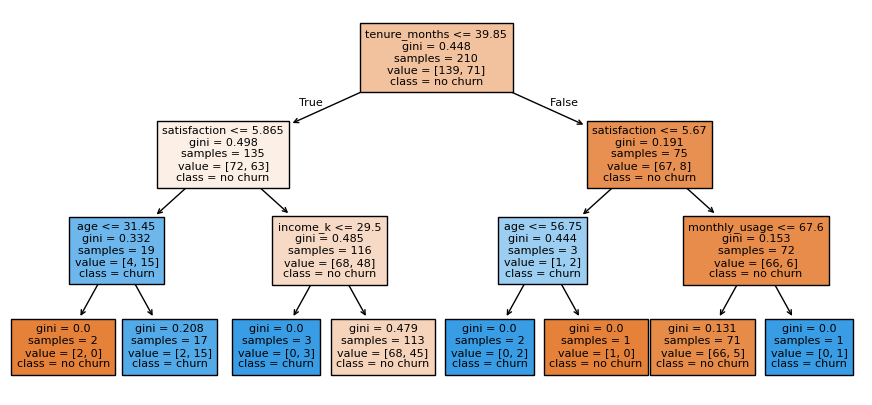

In [4]:
small_tree = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=0).fit(Xtr, ytr)
fig, ax = plt.subplots(figsize=(11, 5))
plot_tree(small_tree, feature_names=features, class_names=["no churn", "churn"], filled=True, fontsize=8, ax=ax)
plt.show()

Read a split as: "if `satisfaction <= threshold`, go left; the Gini/
entropy value at each node measures how mixed the two classes still are
there -- the root's split is whichever feature/threshold most reduces that
impurity, exactly the "splitting criteria" definition."

## Overfitting and pruning

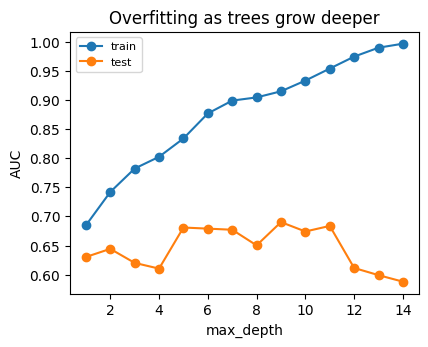

Best depth on this split: 9


In [5]:
depths = range(1, 15)
train_aucs, test_aucs = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xtr, ytr)
    train_aucs.append(roc_auc_score(ytr, m.predict_proba(Xtr)[:, 1]))
    test_aucs.append(roc_auc_score(yte, m.predict_proba(Xte)[:, 1]))

fig, ax = plt.subplots(figsize=(4.5, 3.4))
ax.plot(depths, train_aucs, marker="o", label="train")
ax.plot(depths, test_aucs, marker="o", label="test")
ax.set_xlabel("max_depth"); ax.set_ylabel("AUC"); ax.set_title("Overfitting as trees grow deeper")
ax.legend(fontsize=8)
plt.show()
best_depth = depths[int(np.argmax(test_aucs))]
print("Best depth on this split:", best_depth)

Train AUC keeps climbing with depth (an unpruned tree can memorise the
training set); test AUC peaks then flattens or drops -- exactly the gap
cost-complexity/error-reduced pruning are designed to close, by cutting
back branches that only help on the training data.

In [6]:
clf = DecisionTreeClassifier(max_depth=best_depth, random_state=0).fit(Xtr, ytr)

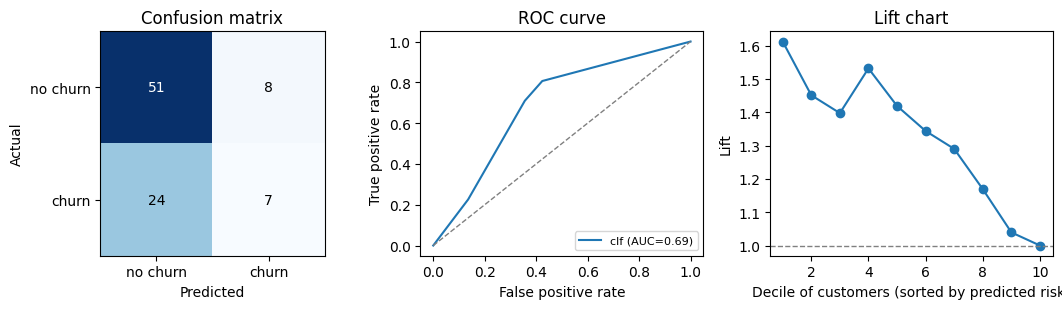

AUC: 0.69


In [7]:
y_pred = clf.predict(Xte)
y_score = clf.predict_proba(Xte)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
plot_confusion(yte, y_pred, ax=axes[0])
auc_val = plot_roc(yte, y_score, ax=axes[1], label="clf")
plot_lift(yte, y_score, ax=axes[2])
plt.tight_layout(); plt.show()
print("AUC:", round(auc_val, 3))

**Wrap-up**: a pruned decision tree is fully interpretable (you can read
every decision path) but a single tree's boundary is blocky/high-variance
-- Section 3.6 (Ensembles) fixes exactly that by combining many trees.